# 06 - Exploratory Data Analysis (EDA)

**Goal:** understand the medicine market in the dataset: who makes the medicines, in which forms, how many brands compete on the same generic, and how prices are spread.

**Source:** `data/medicine.db` (built from the cleaned CSVs; identical content to `MedicineDB` in SQL Server).

**Rules kept from the project:** no invented data, NULL prices stay NULL, no availability claims (the dataset has no pharmacy/stock data).

In [1]:
import sqlite3, pandas as pd, numpy as np, matplotlib.pyplot as plt
from pathlib import Path
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
con = sqlite3.connect(ROOT / "data" / "medicine.db")      # read-only analysis, nothing is modified
FIG = ROOT / "reports" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
C = "#2a6f97"
def bar(s, title, fname, xlabel="", n=15):
    s = s.head(n).iloc[::-1]
    ax = s.plot.barh(color=C, figsize=(8, 0.35*len(s)+1.2)); ax.set_title(title, loc="left", fontweight="bold"); ax.set_ylabel(""); ax.set_xlabel(xlabel)
    for i, v in enumerate(s.values): ax.text(v, i, f" {v:,.0f}", va="center", fontsize=8)
    plt.tight_layout(); plt.savefig(FIG/fname); plt.show()

## 1. Dataset at a glance

In [2]:
kpi = pd.read_sql("""
SELECT (SELECT COUNT(*) FROM medicines)      AS medicines,
       (SELECT COUNT(*) FROM generics)       AS generics,
       (SELECT COUNT(*) FROM manufacturers)  AS manufacturers,
       (SELECT COUNT(*) FROM dosage_forms)   AS dosage_forms,
       (SELECT COUNT(*) FROM drug_classes)   AS drug_classes,
       (SELECT COUNT(*) FROM indications)    AS indications,
       (SELECT COUNT(price) FROM medicines)  AS priced,
       (SELECT ROUND(100.0*COUNT(price)/COUNT(*),2) FROM medicines) AS price_coverage_pct""", con)
kpi.T.rename(columns={0:"value"})

,value
medicines,21714.00
generics,1711.00
manufacturers,240.00
dosage_forms,113.00
drug_classes,421.00
indications,2043.00
priced,20357.00
price_coverage_pct,93.75


In [3]:
med = pd.read_sql("SELECT * FROM vw_medicine_details", con)
print(med.type.value_counts().to_string())
print("\nMissing values per column (medicine details view):")
miss = med.isna().sum().sort_values(ascending=False); print(miss[miss>0].to_string())

type
allopathic    21363
herbal          351

Missing values per column (medicine details view):
pack_size              8187
pack_price             8187
indication_name        1713
price                  1357
drug_class_name         985
strength                849
strength_normalized     849
package_description      42
generic_name              2


## 2. Who makes the medicines? (manufacturers)

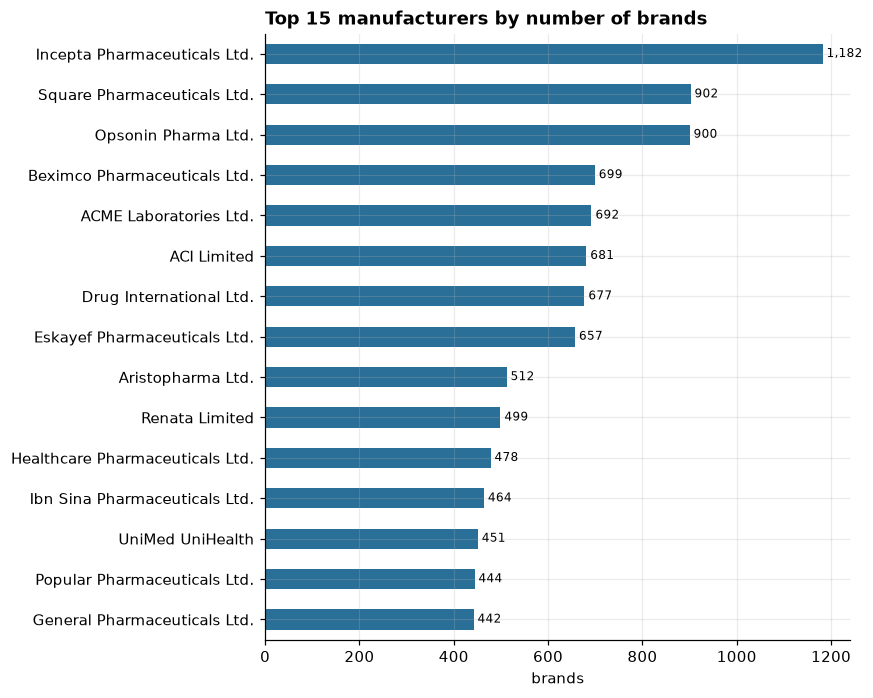

Top 10 manufacturers hold 34.1% of all brands; 232 manufacturers in total; median brands per manufacturer = 28


In [4]:
mf = med.groupby("manufacturer_name").size().sort_values(ascending=False)
bar(mf, "Top 15 manufacturers by number of brands", "eda_top_manufacturers.png", "brands")
top10 = mf.head(10).sum()/mf.sum()
print(f"Top 10 manufacturers hold {top10:.1%} of all brands; {len(mf)} manufacturers in total; median brands per manufacturer = {mf.median():.0f}")

## 3. Dosage forms

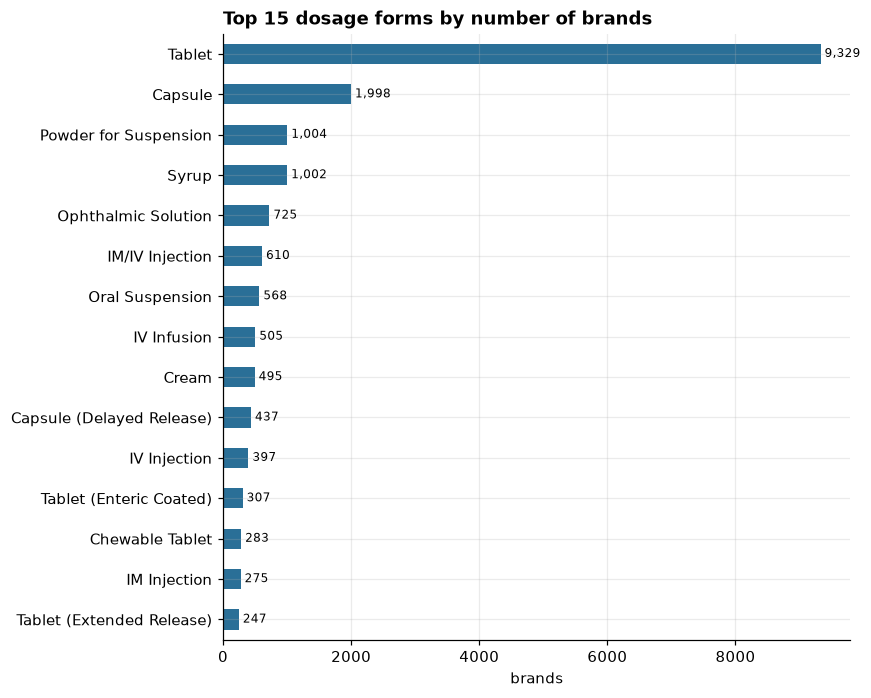

Tablet + Capsule + Syrup share: 56.8%


In [5]:
df_ = med.groupby("dosage_form_name").size().sort_values(ascending=False)
bar(df_, "Top 15 dosage forms by number of brands", "eda_top_forms.png", "brands")
print(f"Tablet + Capsule + Syrup share: {df_[['Tablet','Capsule','Syrup']].sum()/df_.sum():.1%}")

## 4. Generics and competition (how many brands per generic?)

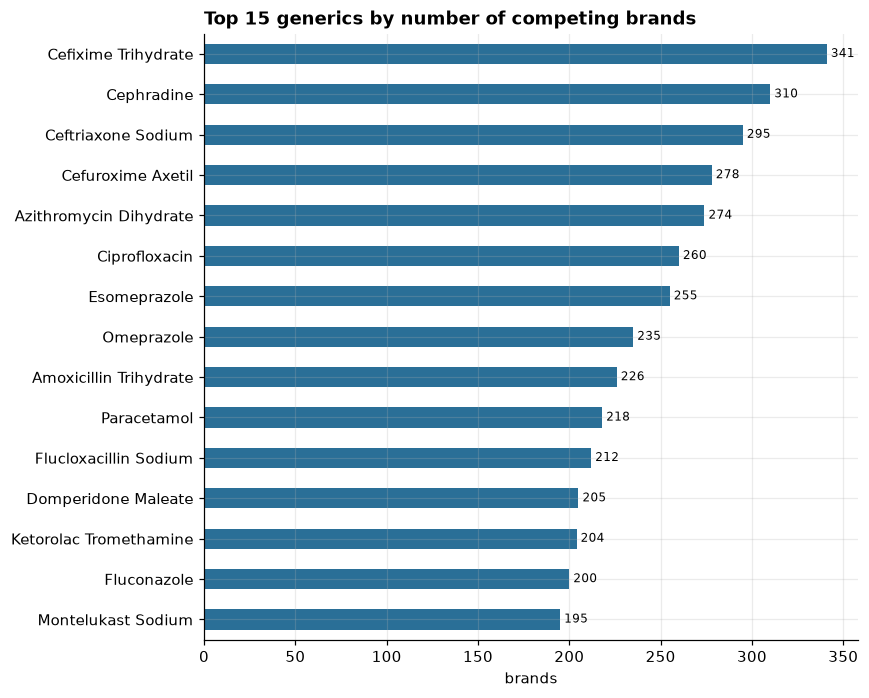

brand_count
0          50
1         446
2-5       562
6-20      423
21-100    190
100+       40


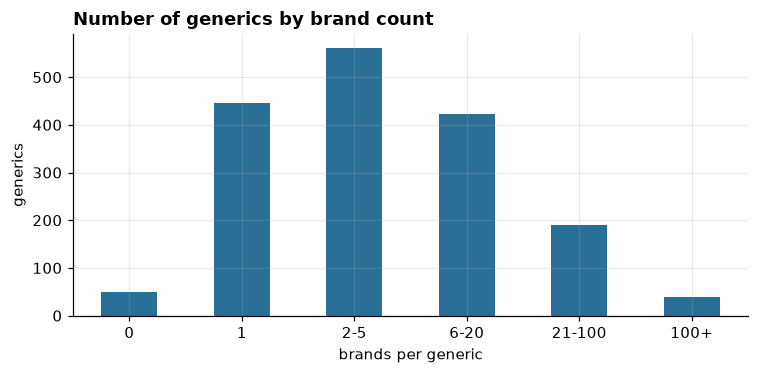


Median brands per generic = 3; mean = 12.7  (a few generics have hundreds of brands, most have very few)


In [6]:
gb = pd.read_sql("SELECT * FROM vw_generic_brand_counts", con).sort_values("brand_count", ascending=False)
bar(gb.set_index("generic_name").brand_count, "Top 15 generics by number of competing brands", "eda_top_generics.png", "brands")
bins = pd.cut(gb.brand_count, [-1,0,1,5,20,100,10_000], labels=["0","1","2-5","6-20","21-100","100+"])
print(bins.value_counts().sort_index().to_string())
fig, ax = plt.subplots(figsize=(7,3.5)); bins.value_counts().sort_index().plot.bar(ax=ax, color=C, rot=0)
ax.set_title("Number of generics by brand count", loc="left", fontweight="bold"); ax.set_xlabel("brands per generic"); ax.set_ylabel("generics"); plt.tight_layout(); plt.savefig(FIG/"eda_brands_per_generic.png"); plt.show()
print(f"\nMedian brands per generic = {gb.brand_count.median():.0f}; mean = {gb.brand_count.mean():.1f}  (a few generics have hundreds of brands, most have very few)")

## 5. Drug classes and indications

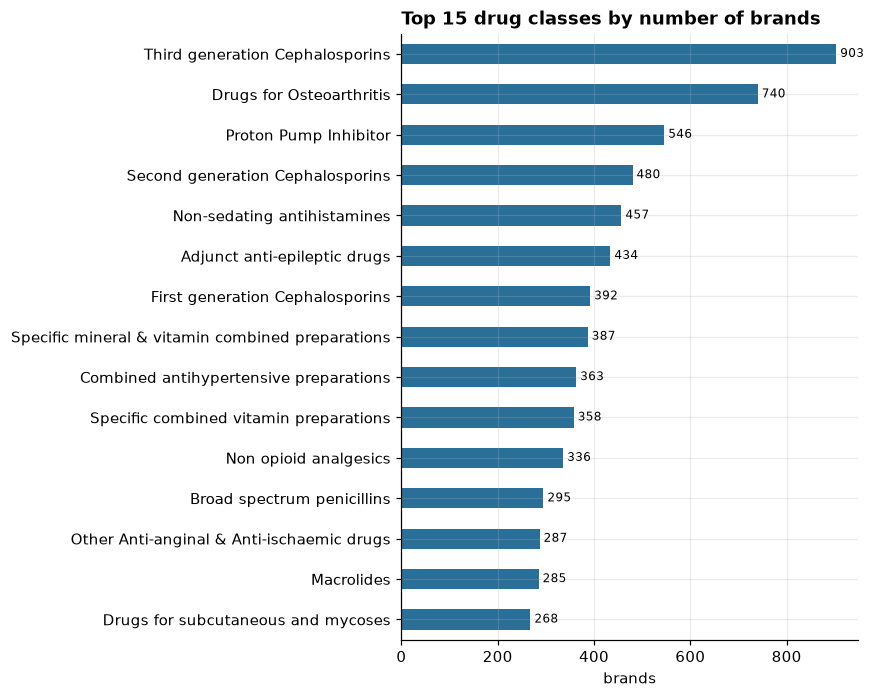

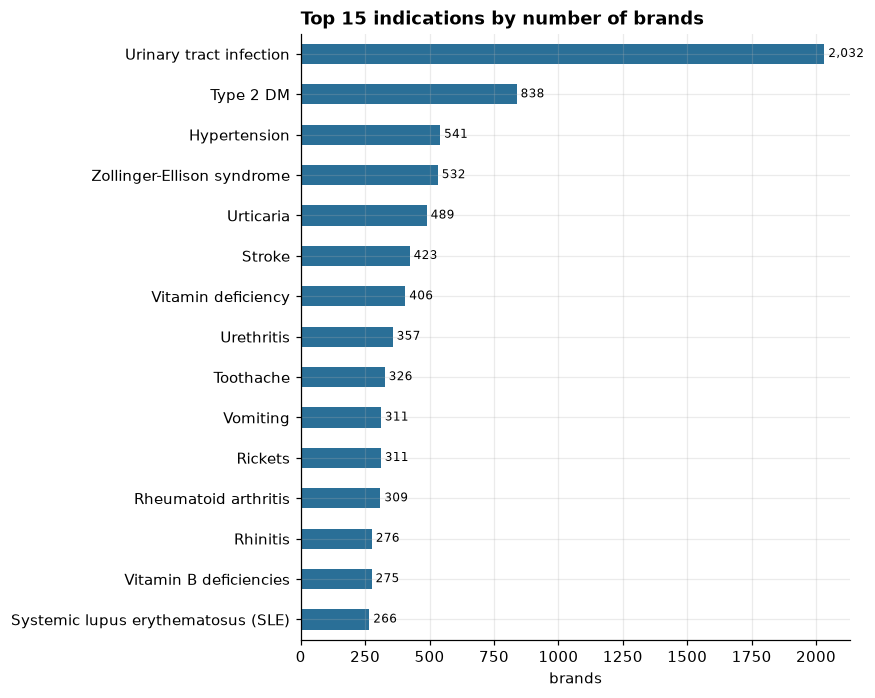

In [7]:
dc = med.dropna(subset=["drug_class_name"]).groupby("drug_class_name").size().sort_values(ascending=False)
bar(dc, "Top 15 drug classes by number of brands", "eda_top_classes.png", "brands")
ind = med.dropna(subset=["indication_name"]).groupby("indication_name").size().sort_values(ascending=False)
bar(ind, "Top 15 indications by number of brands", "eda_top_indications.png", "brands")

## 6. Price distribution

`price` is the **unit price** for tablets/capsules/ampoules and the **price of the described container** for syrups, drops, vials, etc. So prices are only compared **within the same dosage form**, never averaged across all forms.

count     20357.00
mean        349.99
std        4760.36
min           0.12
25%           6.00
50%          15.05
75%          60.22
95%         500.00
99%        3629.04
max      340000.00


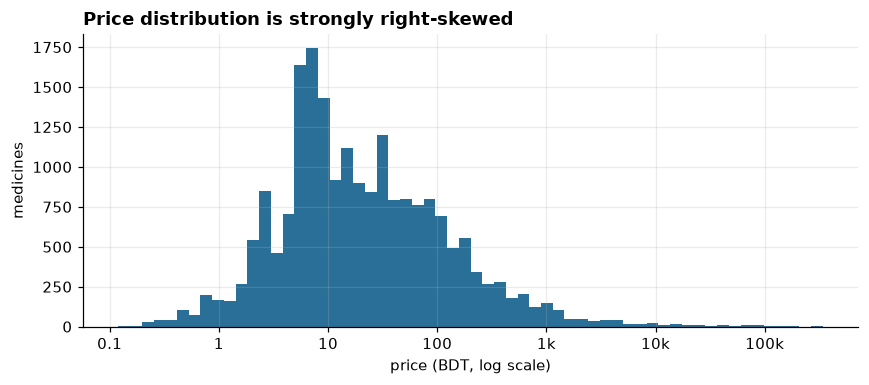


Mean vs median -> the mean is pulled up by a few very expensive biologic/oncology products: 350.0 vs 15.0


In [8]:
p = med.dropna(subset=["price"])
print(p.price.describe(percentiles=[.25,.5,.75,.95,.99]).round(2).to_string())
fig, ax = plt.subplots(figsize=(8,3.6)); ax.hist(np.log10(p.price), bins=60, color=C)
ax.set_xticks([-1,0,1,2,3,4,5]); ax.set_xticklabels(["0.1","1","10","100","1k","10k","100k"]); ax.set_xlabel("price (BDT, log scale)"); ax.set_ylabel("medicines")
ax.set_title("Price distribution is strongly right-skewed", loc="left", fontweight="bold"); plt.tight_layout(); plt.savefig(FIG/"eda_price_hist.png"); plt.show()
print("\nMean vs median -> the mean is pulled up by a few very expensive biologic/oncology products:", round(p.price.mean(),1), "vs", round(p.price.median(),1))

C:\Users\ASUS-PC\AppData\Local\Temp\ipykernel_27216\3922680336.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(data, vert=False, showfliers=False, patch_artist=True, boxprops=dict(facecolor="#bcd4e6"), medianprops=dict(color="k"))


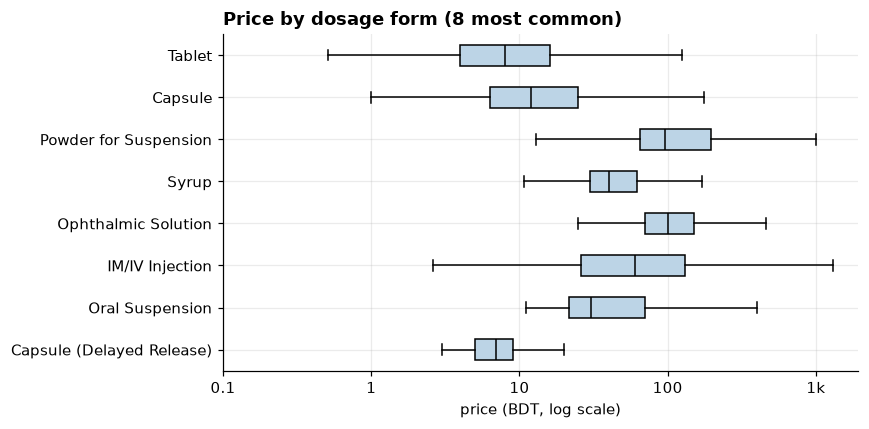

                           count  median    mean      max
dosage_form_name                                         
Tablet                      8991    8.00   35.88  8976.66
Capsule                     1942   12.00   54.66  5220.00
Powder for Suspension        838   96.18  146.73  1000.00
Syrup                        799   40.00   52.53  2385.00
Ophthalmic Solution          718  100.00  144.28  1800.00
IM/IV Injection              604   60.00  163.88  3200.00
Oral Suspension              528   30.44   79.10  2134.00
Capsule (Delayed Release)    421    7.00    7.59    25.00


In [9]:
top_forms = p.dosage_form_name.value_counts().head(8).index
fig, ax = plt.subplots(figsize=(8,4)); data = [np.log10(p[p.dosage_form_name==f].price) for f in top_forms]
ax.boxplot(data, vert=False, showfliers=False, patch_artist=True, boxprops=dict(facecolor="#bcd4e6"), medianprops=dict(color="k"))
ax.set_yticklabels(top_forms); ax.set_xticks([-1,0,1,2,3]); ax.set_xticklabels(["0.1","1","10","100","1k"]); ax.set_xlabel("price (BDT, log scale)"); ax.invert_yaxis()
ax.set_title("Price by dosage form (8 most common)", loc="left", fontweight="bold"); plt.tight_layout(); plt.savefig(FIG/"eda_price_by_form.png"); plt.show()
print(p[p.dosage_form_name.isin(top_forms)].groupby("dosage_form_name").price.agg(["count","median","mean","max"]).round(2).sort_values("count", ascending=False))

In [10]:
print("Most expensive 10 products (check: these are real biologic/oncology prices, see reports/price_validation_report.md)")
p.sort_values("price", ascending=False).head(10)[["brand_name","generic_name","dosage_form_name","manufacturer_name","price"]]

Most expensive 10 products (check: these are real biologic/oncology prices, see reports/price_validation_report.md)


,brand_name,generic_name,dosage_form_name,manufacturer_name,price
16775,Tecentriq,Atezolizumab,IV Infusion,Roche Bangladesh Ltd.,340000.00
19083,Pemro,Pembrolizumab,IV Infusion,Beacon Pharmaceuticals Ltd.,195000.00
15473,Perjeta,Pertuzumab,IV Infusion,Roche Bangladesh Ltd.,175000.00
16312,Kadcyla,Trastuzumab Emtansine,IV Infusion,Roche Bangladesh Ltd.,150500.00
19086,Nivomab,Nivolumab,IV Infusion,Beacon Pharmaceuticals Ltd.,146000.00
12623,Jevtana,Cabazitaxel,IV Infusion,Genzyme Corporation,142687.22
12072,Visudyne,Verteporfin,Injection,Novartis (Bangladesh) Ltd.,137799.79
15475,Gazyva,Obinutuzumab,Injection,Roche Bangladesh Ltd.,112000.00
20736,Ronapreve,Casirivimab + Imdevimab,Injection,Roche Bangladesh Ltd.,106250.00
11276,Simulect,Basiliximab,IV Infusion,Novartis (Bangladesh) Ltd.,103273.56


## 7. EDA takeaways

See the printed numbers above. Main messages for the report:
1. The market is **fairly concentrated**: the top 10 of 232 manufacturers hold about a third of all brands.
2. A handful of generics are **extremely crowded** (hundreds of brands) while most have only a few - competition is uneven.
3. Prices span more than 6 orders of magnitude (0.12 to 340,000 BDT); the **median** (not the mean) describes a typical product, and comparisons must stay within the same dosage form.
4. Next notebook (07) quantifies how much money a patient could save by choosing a cheaper equivalent brand.